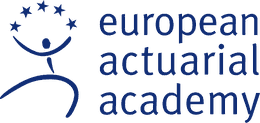

<h1 style="color:#0F2B72;">Fit4AI compact</h1>
<h2 style="color:#0F2B72;">Module 5: Supervised Learning</h2>
<div style="border:0px; background-color:#0F2B72; width:100%; height:1px;">&nbsp;</div>
<h4 style="color:#0F2B72;" class="unlisted unnumbered">EAA Inhouse Seminar SAV | Zurich, 19/20 November 2026</h4>
<p style="color:#0F2B72;">Dr Johannes Schupp<br>Jupyter Notebook (Python)</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/simonhatzesberger/fit4ai-compact-20261119/blob/main/Fit4AI_5_Supervised_Learning.ipynb)

Repository: [simonhatzesberger/fit4ai-compact-20261119](https://github.com/simonhatzesberger/fit4ai-compact-20261119) – code under the [MIT License](https://github.com/simonhatzesberger/fit4ai-compact-20261119/blob/main/LICENSE).

# Use case: motor claim frequency model (French motor dataset) – trees, Random Forest and neural networks in Python

In this notebook, we consider the *French motor dataset “freMTPL2freq”*, a widely used reference dataset in actuarial research and teaching. It comes from the field of French motor third-party liability insurance (Third-Party Liability, TPL). Each row represents an insurance policy or a group of policies with identical features over a specific exposure period.

The central target variable is the number of reported claims (ClaimNb) per policy. One feature is the exposure, which indicates the time during which the policy was exposed to the risk. Further important features include demographic information on the policyholder (e.g. age) and vehicle specifications (e.g. power). In addition, geographical information (region) and risk-related factors such as the bonus-malus level are included.

This notebook is divided into three blocks. The modelling carried out in each block serves first and foremost to illustrate the learning content presented in the course. Individual modelling steps are therefore deliberately kept simple.

**Block 1: Classification model**: For this, a synthetic lapse pattern is added to the dataset and subsequently modelled with a classification tree.

**Block 2: Random Forest regression model**: We use the target variable ClaimNb and model different variants of a Random Forest to represent this target variable. For simplicity, only the numerically coded columns (BonusMalus, Density, DrivAge, Exposure, VehAge, VehPower) of the dataset are used as features for the model. (The columns BonusMalus, VehPower are ordinal features which are, however, numerically coded and are therefore used here nonetheless).

**Block 3: Neural network regression model**: We again model the target variable ClaimNb. In doing so, we use a realistic Poisson loss model and an exposure-weighted target variable.

*References*

- Denuit, M., Maréchal, X., Pitrebois, S., & Walhin, J. F. (2007). *Actuarial modelling of claim counts: Risk classification, credibility and bonus-malus systems*. John Wiley & Sons.
- Wüthrich, M.V. and Richman, R. and Avanzi, B. and Lindholm, M. and Maggi, M. and Mayer, M. and Schelldorfer, J. and Scognamiglio, S. (2025): *AI Tools for Actuaries* Available at: https://ssrn.com/abstract=5162304 or http://dx.doi.org/10.2139/ssrn.5162304


In [1]:
# --- Setup: Google Colab or local Python environment
# In Google Colab, all required packages are preinstalled;
# TensorFlow (Block 3) is installed only if it is missing.
# Locally, install the packages first: pip install -r requirements.txt
import importlib.util
import subprocess
import sys

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and importlib.util.find_spec("tensorflow") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tensorflow"], check=True)

# Load required libraries
import pandas as pd
import numpy as np
import random
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_openml


import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, roc_auc_score, roc_curve

from matplotlib.colors import ListedColormap
from sklearn.preprocessing import QuantileTransformer

We load the dataset from an online repository. The dataset is very widely used and there are countless download options (including *CASdatasets*).
In addition to the target variable (ClaimNb) and the exposure, the dataset contains nine further features. These comprise both numerical and categorical features.


In [2]:
# Read in data

print("Data import...")
ds = fetch_openml(data_id=41214, as_frame=True)
data = ds.frame

# Delete ID column
data = data.drop('IDpol', axis=1)
display(data.head())

Data import...


,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1,0.10,D,5,0,55,50,B12,'Regular',1217,R82
1,1,0.77,D,5,0,55,50,B12,'Regular',1217,R82
2,1,0.75,B,6,2,52,50,B12,'Diesel',54,R22
3,1,0.09,B,7,0,46,50,B12,'Diesel',76,R72
4,1,0.84,B,7,0,46,50,B12,'Diesel',76,R72


<h2 style="color:#0050A0;">Block 1: Classification tree, overfitting, underfitting, generalisation</h2>


First, we want to solve a classification problem. To do so, we generate a synthetic target variable with the categories 0/1 which indicates whether an insured risk will lapse in the following year. As the data were recorded over a longer period, this information has been recorded conclusively and completely (no censored or incomplete data).

*The target variable is a synthetically generated variable which exhibits a certain pattern on the unit square (2D). This pattern is not representative of actual lapse patterns and serves exclusively to illustrate classification trees.*

<div class="alert alert-block alert-info">
<b>Procedure in this block:</b> 
    
- *Preparation:* First, we select two features based on the dataset (DrivAge, BonusMalus/Density + VehAge) and transform them so that they are uniformly distributed on the unit square.
- *Preparation:* We then define the lapse pattern and simulate lapses.
- Training of 3 different classification trees
- Evaluation based on the AUC on training / test data
- Graphical evaluation based on prediction regions on training data
</div>





In [3]:
# Preparation: transformation of two columns to the unit square - basis for the lapse pattern
qt = QuantileTransformer(output_distribution='uniform', 
                         n_quantiles=30,
                         random_state=42,
                         subsample=10**5) 

# --- Transformation of the column DrivAge ---
data['DrivAge_norm'] = qt.fit_transform(data[['DrivAge']])
print("The new column 'DrivAge_norm' is now uniformly distributed on [0, 1].")


# --- Transformation of the column BonusMalus ---
MIN_DENSITY = 100 
safedensity= np.where(data['Density'] < MIN_DENSITY, MIN_DENSITY, data['Density'])

data['Lapse_Pattern_Dim2'] = data['BonusMalus']  / safedensity + data['VehAge']
data['BonusMalus/Density_norm'] = qt.fit_transform(data[['Lapse_Pattern_Dim2']])

print("The new column 'BonusMalus/Density_norm' is now also uniformly distributed on [0, 1].")

The new column 'DrivAge_norm' is now uniformly distributed on [0, 1].
The new column 'BonusMalus/Density_norm' is now also uniformly distributed on [0, 1].


In [4]:
# Preparation: define and simulate the lapse pattern
def generate_sharper_wavy_data(n_samples=5000,X= np.random.rand(5000, 2)):
    """
    Generates a complex, wavy pattern with sharp boundaries.
    """
    k1, k2, k3 = 7, 5, 3  
    A1, A2, A3 = 2.0, 1.5, 3.0
    
    wavy = (
        A1 * np.sin(k1 * np.pi * X[:, 0]) +       
        A2 * np.cos(k2 * np.pi * X[:, 1]) +       
        A3 * np.sin(k3 * np.pi * X[:, 0] * X[:, 1]) 
    )
    
    # Unstructured noise
    random.seed(42)
    np.random.seed(42)
    unstructurednoise = np.random.normal(0, 2, n_samples) 
    latent = wavy + unstructurednoise
    
    # Soft boundary with a high sharpness factor (clear boundary)
    sharpness = 5.0 
    probability_p = 1 / (1 + np.exp(-sharpness * latent))
    
    # Class assignment by drawing from the Bernoulli distribution
    y_noisy = (np.random.rand(n_samples) > probability_p).astype(int)
    
    return X, y_noisy


# Simulate data
X, y = generate_sharper_wavy_data(n_samples=data.shape[0],X = data[['DrivAge_norm','BonusMalus/Density_norm']].values) 
data['Lapse'] = y
display(data.head())

,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,DrivAge_norm,Lapse_Pattern_Dim2,BonusMalus/Density_norm,Lapse
0,1,0.10,D,5,0,55,50,B12,'Regular',1217,R82,0.758621,0.041085,0.022563,0
1,1,0.77,D,5,0,55,50,B12,'Regular',1217,R82,0.758621,0.041085,0.022563,1
2,1,0.75,B,6,2,52,50,B12,'Diesel',54,R22,0.689655,2.500000,0.258686,0
3,1,0.09,B,7,0,46,50,B12,'Diesel',76,R72,0.551724,0.500000,0.068966,0
4,1,0.84,B,7,0,46,50,B12,'Diesel',76,R72,0.551724,0.500000,0.068966,0


We now train several decision trees with different configurations regarding the tree depth and the minimum number of observations per terminal leaf.

- Tree 1: maximum depth 20, at least 10 observations in each leaf
- Tree 2: maximum depth 8, at least 100 observations in each leaf
- Tree 3: maximum depth 3, unrestricted number of observations in each leaf. Due to the small number of branching levels, there are necessarily many observations in each leaf, so that this hyperparameter is not important here.

We split the data into training and test data in a ratio of 70% to 30%.


In [5]:
# Define functions for visualising classification trees and the performance
def plot_large_dataset_decision_regions(X, Y, model, resolution=200, 
                                        sample_size=1000, point_alpha=0.2, name = ""):
    """
    Visualises the decision regions and a sample of the observations 
    with transparency (alpha).
    """
    
    # Draw a random sample (do not plot all points)
    if X.shape[0] > sample_size:
        # Generates random indices
        rng = np.random.default_rng(seed=42)
        
        sample_indices = rng.choice(X.shape[0], sample_size, replace=False)
        Xplot = X[sample_indices]
        Yplot = Y[sample_indices]
    else:
        Xplot = X
        Yplot = Y

    # Setup for the decision regions
    x1min, x1max = 0, 1
    x2min, x2max = 0, 1
    
    x1_coords = np.linspace(x1min, x1max, resolution)
    x2_coords = np.linspace(x2min, x2max, resolution)
    xx1, xx2 = np.meshgrid(x1_coords, x2_coords)
    grid_points = np.c_[xx1.ravel(), xx2.ravel()]
    Z = model.predict(grid_points).reshape(xx1.shape)

    # Plotting
    plt.figure(figsize=(4, 4))
    plt.title(name)
    plt.title(f'Decision regions for {name}')
    plt.xlim(x1min, x1max)
    plt.ylim(x2min, x2max)
    
    # Define colours
    cmap_light = ListedColormap(['orange', 'cyan'])
    cmap_bold = ListedColormap(['darkorange', 'darkcyan']) 
    
    # Drawing the decision regions (rectangles)
    plt.contourf(xx1, xx2, Z, cmap=cmap_light, alpha=0.5)
    
    # Drawing the observation points (points)
    scatter = plt.scatter(Xplot[:, 0], Xplot[:, 1], c=Yplot, cmap=cmap_bold, 
                          edgecolor='k', s=50, 
                          alpha=point_alpha) 

    # Create legend
    legend1 = plt.legend(*scatter.legend_elements(),
                         loc="lower left", title="Class")
   
    plt.gca().add_artist(legend1)
    
    plt.grid(True, linestyle='--', alpha=0.6)
    if len(name) > 1:
        plt.savefig(name)
    plt.show()


def evaluate_auc(model, X_train, y_train, X_test, y_test, label):
    """
    Determines the AUC for training and test and prints it to the console
    """
    # Prediction on training data
    y_train_prob = model.predict_proba(X_train)[:, 1]
    fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)
    auc_train = roc_auc_score(y_train, y_train_prob)
    
    # Prediction on test data
    y_test_prob = model.predict_proba(X_test)[:, 1]
    fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)
    auc_test = roc_auc_score(y_test, y_test_prob)
    
    print(f"--- {label} ---")
    print(f"AUC Train: {auc_train:.4f}")
    print(f"AUC Test:  {auc_test:.4f}")
    print("-" * 30)

    # Plotting the ROC curves
    plt.figure(figsize=(5, 5))
    plt.plot(fpr_train, tpr_train, color='blue', lw=2,
             label=f'Train ROC (AUC = {auc_train:.2f})')
    plt.plot(fpr_test, tpr_test, color='darkorange', lw=2,
             label=f'Test ROC (AUC = {auc_test:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')

    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC for {label}')
    plt.legend(loc="lower right")
    plt.grid(True)
    if len(label) > 1:
        plt.savefig(label)
    plt.show()

--- Start Tree 1 ---
--- Tree Overfitting ---
AUC Train: 0.9016
AUC Test:  0.8496
------------------------------


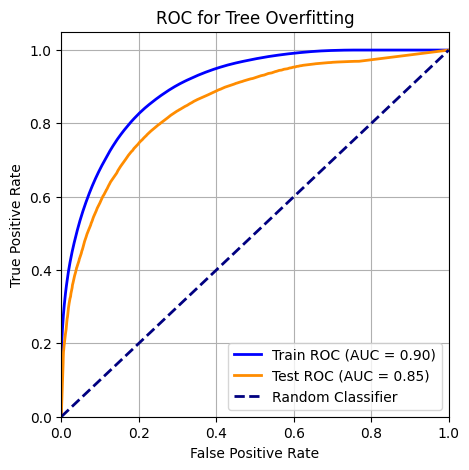

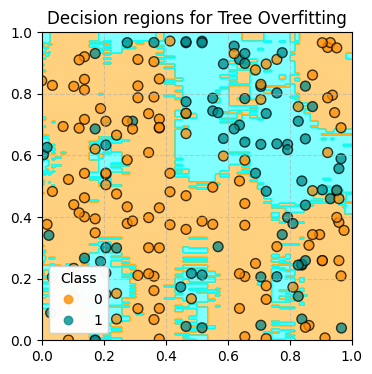

--- Start Tree 2 ---
--- Tree Generalisation ---
AUC Train: 0.8697
AUC Test:  0.8679
------------------------------


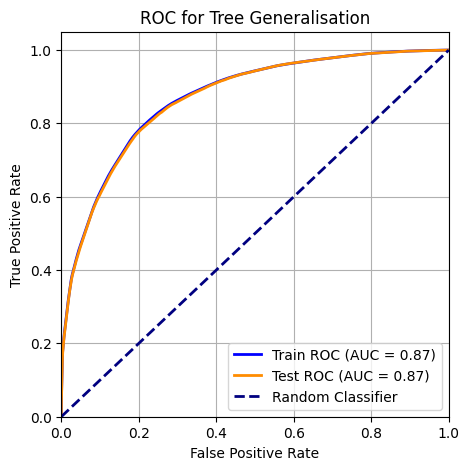

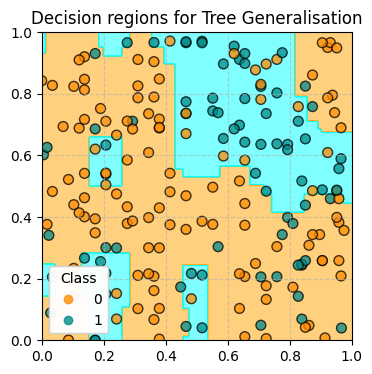

--- Start Tree 3 ---
--- Tree Underfitting ---
AUC Train: 0.7599
AUC Test:  0.7603
------------------------------


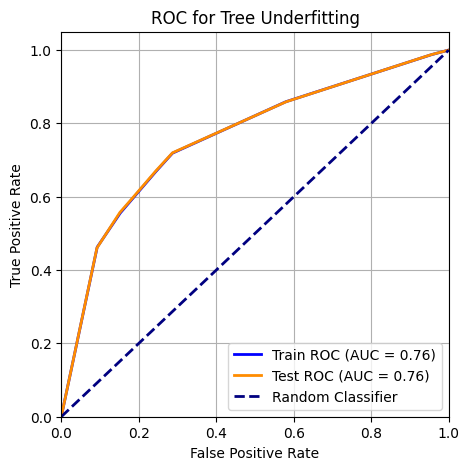

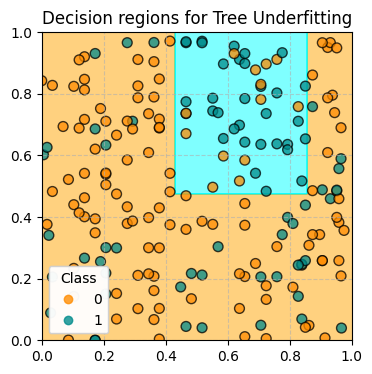

In [6]:
# Split training / test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Tree 1 
print(f"--- Start Tree 1 ---")
tree_overfit = DecisionTreeClassifier(
    criterion='gini',
    max_depth=20,  #or None,      
    min_samples_leaf=10,
    random_state=42
)
tree_overfit.fit(X_train, y_train)


evaluate_auc(tree_overfit, X_train, y_train, X_test, y_test, "Tree Overfitting")
predictions = tree_overfit.predict(X_train)

plot_large_dataset_decision_regions(X_train,y_train, tree_overfit, 
                                    sample_size=200, 
                                    point_alpha=0.75,
                                    name = 'Tree Overfitting')


# Tree 2
print(f"--- Start Tree 2 ---")
tree_good = DecisionTreeClassifier(
    criterion='gini',
    max_depth=8,           # Not too deep
    min_samples_leaf=100,  # Many samples for reliable probabilities
    random_state=42
)
tree_good.fit(X_train, y_train)

evaluate_auc(tree_good, X_train, y_train, X_test, y_test, "Tree Generalisation")
predictions = tree_good.predict(X_train)

plot_large_dataset_decision_regions(X_train,y_train,  tree_good, 
                                    sample_size=200, 
                                    point_alpha=0.75,
                                    name = 'Tree Generalisation')
# Tree 3 
print(f"--- Start Tree 3 ---")
tree_underfit = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=42
)
tree_underfit.fit(X_train, y_train)

evaluate_auc(tree_underfit, X_train, y_train, X_test, y_test, "Tree Underfitting")
predictions = tree_underfit.predict(X_train)


plot_large_dataset_decision_regions(X_train,y_train,  tree_underfit, 
                                    sample_size=200, 
                                    point_alpha=0.75,
                                    name = 'Tree Underfitting')

<h3 style="color:#0050A0;">Making the tree structure visible</h3>

The plots above show the decision regions of the three trees. A decision tree constructs these regions through *binary splits*, i.e. through a sequence of yes/no questions on the features. To see this *divide-and-conquer* principle directly, we display the tree structure of *Tree 3* (`max_depth=3`); it is shallow enough to remain fully readable. 

Each node shows the split rule, the *Gini impurity* (`gini`), the number of observations (`samples`) and the class distribution (`value`); the coloured *leaves* correspond to the predicted class (`class`). 

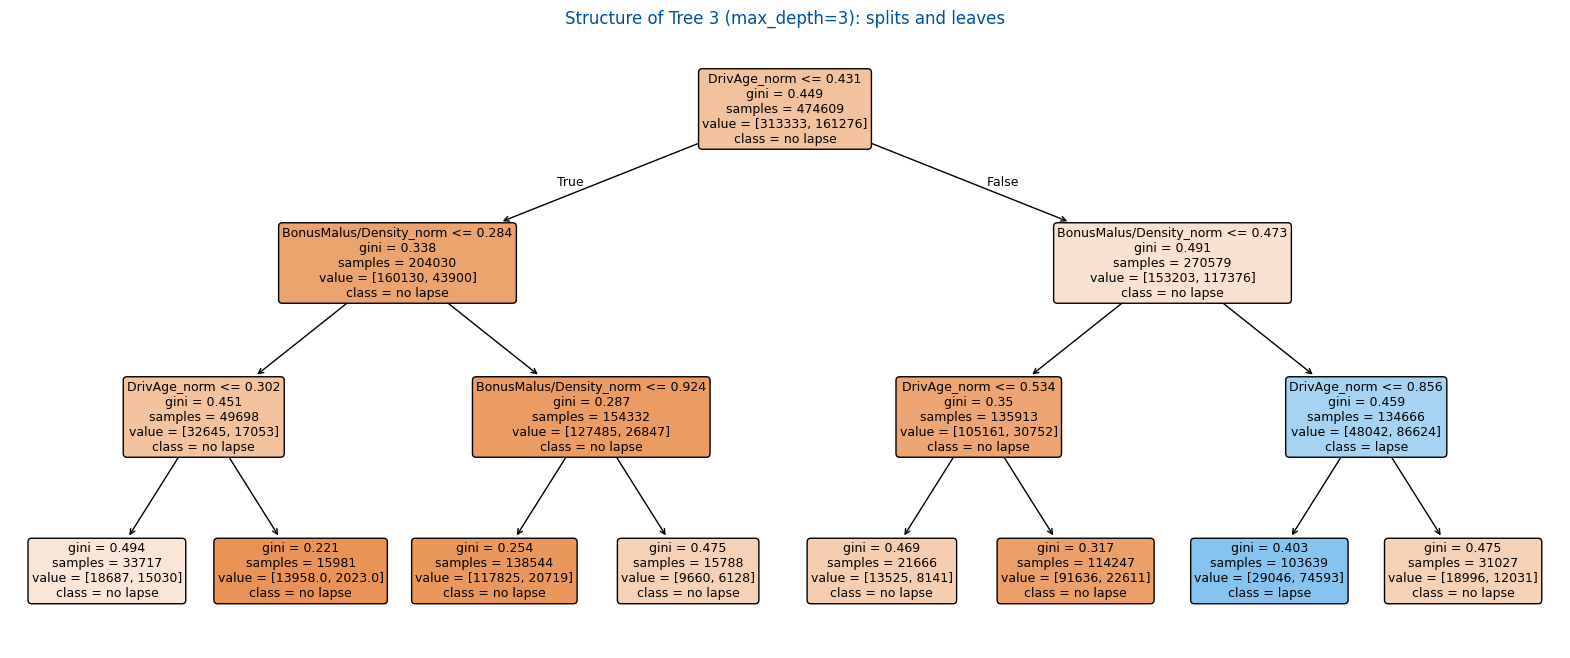

In [7]:
# Visualisation of the tree structure of Tree 3 
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(
    tree_underfit,
    feature_names=['DrivAge_norm', 'BonusMalus/Density_norm'],
    class_names=['no lapse', 'lapse'],
    filled=True,
    rounded=True,
    impurity=True,
    fontsize=9,
    ax=ax,
)
ax.set_title('Structure of Tree 3 (max_depth=3): splits and leaves', color='#0050A0')
plt.show()

<h2 style="color:#0050A0;">Block 2: Regression trees – Random Forest</h2>


*Simplification*:

- In this block, we use only the numerical features. This results in significantly faster run times.
- Categorical features can be converted analogously (e.g. via one-hot encoding) into numerical features, so that the algorithms can subsequently process these features analogously.


<div class="alert alert-block alert-info">
<b>Procedure in this block:</b> 
    
- Splitting the dataset into training and test data in a customary ratio (70% to 30%). Other splits (e.g. 80% to 20%) would also be permissible given the size of the data.
- Creation of a bootstrapping approach
- Examination of the correlation of predictions for feature bagging, in order to illustrate how the predictions of the individual trees become less correlated.
- Creation of a Random Forest
</div>






In [8]:
# Data preparation and training / test split
data = ds.frame

# Remove ID column
data = data.drop('IDpol', axis=1)
display(data.head())

# For simplicity, we only use the numerical columns
X = data.drop('ClaimNb', axis=1).select_dtypes(include=np.number)
y = data['ClaimNb'].astype(float) # Target variable as float for the regression

# Data split into training and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print(f"\nTraining set size: {len(X_train)} | Test set size: {len(X_test)}")
print("-" * 40)
print(f"Features used: {list(X.columns)}")


,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1,0.10,D,5,0,55,50,B12,'Regular',1217,R82
1,1,0.77,D,5,0,55,50,B12,'Regular',1217,R82
2,1,0.75,B,6,2,52,50,B12,'Diesel',54,R22
3,1,0.09,B,7,0,46,50,B12,'Diesel',76,R72
4,1,0.84,B,7,0,46,50,B12,'Diesel',76,R72



Training set size: 474609 | Test set size: 203404
----------------------------------------
Features used: ['Exposure', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'Density']


In [9]:
# Visualise the performance of a RandomForest model with an increasing number of trees
def evaluate_progression_ensemble(model, MAX_ESTIMATORS, X_train,X_test,name):
    """
    Display the training progress for training and test as well as for the OOB samples
    """
    # Creating the storage objects
    train_mses = []
    test_mses = []
    oob_mses = []
    estimator_counts = list(range(1, MAX_ESTIMATORS + 1))

    n_train_samples = X_train.shape[0]
    train_preds_sum = np.zeros(n_train_samples)
    test_preds_sum = np.zeros(X_test.shape[0])
    oob_preds_sum = np.zeros(n_train_samples)
    
    # Store how many trees contributed to the prediction in each case for oob
    oob_tree_counts = np.zeros(n_train_samples)

    # Iteration over trees
    for i, tree in enumerate(model.estimators_):
        n_trees = i + 1
    
        # Standard train/test prediction
        train_pred = tree.predict(X_train.values)
        train_preds_sum += train_pred
        test_preds_sum += tree.predict(X_test.values)
    
        # Calculation of the current average prediction
        train_pred_avg = train_preds_sum / n_trees
        test_pred_avg = test_preds_sum / n_trees
    
        # MSE
        train_mses.append(mean_squared_error(y_train, train_pred_avg))
        test_mses.append(mean_squared_error(y_test, test_pred_avg))
    
        # OOB    
        in_bag_indices = model.estimators_samples_[i]
        oob_mask = np.ones(n_train_samples, dtype=bool)
        oob_mask[in_bag_indices] = False
        oob_indices = np.where(oob_mask)[0]
    
        if len(oob_indices) > 0:
            # Predictions for OOB 
            oob_tree_predictions = tree.predict(X_train.iloc[oob_indices].values)
        
            # Adjust OOB sum
            oob_preds_sum[oob_indices] += oob_tree_predictions
        
            oob_tree_counts[oob_indices] += 1
    
        # Observations with at least one tree
        valid_oob_mask = oob_tree_counts > 0
    
        if np.any(valid_oob_mask):
            # OOB predictions
            oob_avg_preds = oob_preds_sum[valid_oob_mask] / oob_tree_counts[valid_oob_mask]
        
            # MSE
            oob_mse = mean_squared_error(y_train[valid_oob_mask], oob_avg_preds)
            oob_mses.append(oob_mse)
        else:
            oob_mses.append(np.nan)

# Plotting
    plt.figure(figsize=(5, 4))
    plt.plot(estimator_counts, train_mses, label='Training MSE ', color='blue', linestyle='--')
    plt.plot(estimator_counts, test_mses, label='Test MSE', color='red')
    valid_oob_mses = [mse for mse in oob_mses if not np.isnan(mse)]
    valid_counts = estimator_counts[-len(valid_oob_mses):]
    plt.plot(valid_counts, valid_oob_mses, label='OOB MSE (Internal validation on training data)', color='green', linewidth=2)

    plt.xlabel('Number of trees (n_estimators)')
    plt.ylabel('Mean Squared Error (MSE) - Lower is better')
    plt.title(name + ' Performance vs. number of trees')
    plt.ylim(bottom=0)
    plt.legend()
    plt.grid(True)
    plt.savefig(name)
    plt.show()

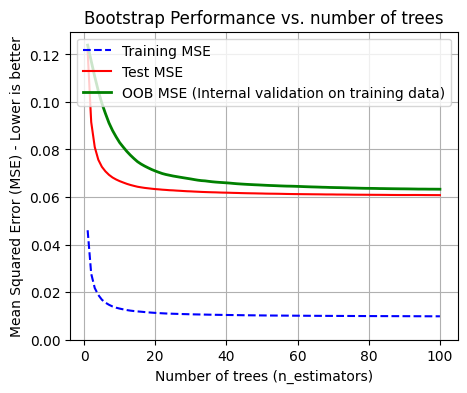

In [10]:
# Training Regressor Model - max_features = X.shape[1] ensures that all features are used -> bootstrapping only
MAX_ESTIMATORS = 100
rfr = RandomForestRegressor(n_estimators=MAX_ESTIMATORS, 
                            max_features=X.shape[1],
                            random_state=42, 
                            oob_score=True, n_jobs=-1) 
rfr.fit(X_train, y_train)
evaluate_progression_ensemble(rfr,MAX_ESTIMATORS, X_train, X_test, name = 'Bootstrap')

**Interpretation**

We see that the OOB predictions are an excellent indicator for new, unseen data (analogous to the test data).
For each tree, the number of features was set to the total number of features in the tree. Differences between the trees result exclusively from the bootstrap approach.
Therefore, the predictions of the trees are still quite strongly correlated. In the next step, we therefore examine how a reduction in the maximum permitted number of features per split affects the correlation of predictions. This constitutes the motivation for feature bagging.

To do so, we will train p Random Forest models, where p corresponds to the number of features (6 in total) (first a Random Forest with only one feature, then two, etc.). For each Random Forest, we compare the predictions of the individual trees (MAX_ESTIMATORS in each case) on the training data and can subsequently estimate the correlation from these prediction vectors. In doing so, we ensure via bootstrap=False that all training records are used in each case.

- The Random Forest with all features therefore develops the same prediction for every individual tree. The correlation is therefore, as expected, 1.
- The fewer features are (randomly) available at each split, the more different the predictions become. The correlation decreases.

Via min_samples_leaf = 1000, we ensure that individual trees do not become too deep, so that the trees generalise well even when considered on training data.

In [11]:
# Training Regressor Model - max_features = i (iterator of the for loop) ensures that more and more features are used -> feature bagging.
MAX_ESTIMATORS = 100
average_correlation = []
corr_matrix_list =[]

for i in range(1,X.shape[1]+1):
    rfr = RandomForestRegressor(n_estimators=MAX_ESTIMATORS, 
                            max_features=i,
                            bootstrap=False, #no bootstrapping --> pure feature bagging
                            min_samples_leaf= 1000,
                            random_state=42, 
                            n_jobs=-1) 
    rfr.fit(X_train, y_train)

    individual_tree_predictions = np.zeros(( X_train.shape[0], MAX_ESTIMATORS))

    for j, tree in enumerate(rfr.estimators_):
        individual_tree_predictions[:, j] = tree.predict(X_train.values)

    corr_matrix = np.corrcoef(individual_tree_predictions, rowvar=False)
    average_correlation.append(np.mean(corr_matrix))
    corr_matrix_list.append(corr_matrix)

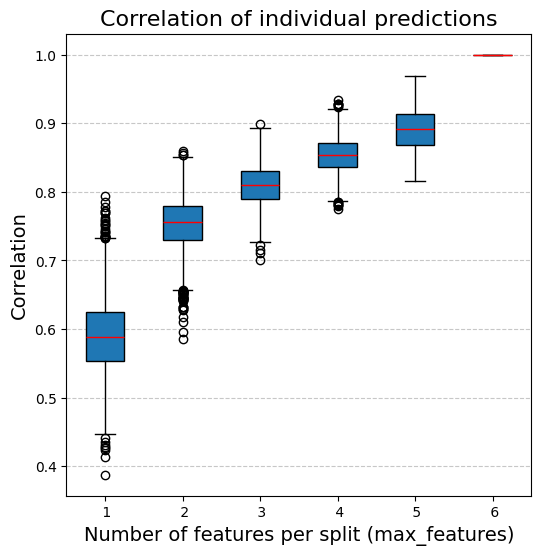

In [12]:
# Extracting the correlation matrices and visualisation
def get_upper_triangle_values(matrix):
    """Extracts the values of the upper triangular matrix (without the diagonal)."""
    # k=1 excludes the diagonal
    rows, cols = np.triu_indices_from(matrix, k=1)
    return matrix[rows, cols]

    
data_for_boxplot = [] 
for matrix in corr_matrix_list:
    # Extract the correlation values for the current matrix/point in time
    upper_values = get_upper_triangle_values(matrix)
    data_for_boxplot.append(upper_values)

# Define the labels for the x-axis
labels = [f' {i + 1}' for i in range(len(data_for_boxplot))]

# --- 3. Plotting the boxplot with Matplotlib ---

plt.figure(figsize=(6, 6))

# plt.boxplot expects a list of data arrays, where each array 
# represents the distribution for one boxplot.
plt.boxplot(
    data_for_boxplot, 
    tick_labels=labels,        # Labelling of the x-axis
    patch_artist=True,    # Allows the boxes to be coloured
    boxprops=dict(facecolor='#1f77b4', color='black'), # Colour of the boxes
    medianprops=dict(color='red') # Colour of the median
)

# Add title and axis labels
plt.title('Correlation of individual predictions', fontsize=16)
plt.xlabel('Number of features per split (max_features)', fontsize=14)
plt.ylabel('Correlation', fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('FeatureBagging')
# Show the plot
plt.show()

**Interpretation**

The correlation of the predictions decreases quickly and noticeably with a decreasing number of features. For simplicity, we use all values of the correlation matrix. This is not a particularly sophisticated approach. Nevertheless, it is clearly evident how the correlation decreases rapidly. The ensemble approach relies on (as far as possible) different individual models being created. A lower correlation is therefore desirable. With too few features, however, the patterns in the dataset are also not recognised well. This therefore represents a further hyperparameter for a tuning step. The principles of the Random Forest – bootstrapping and bagging – have been motivated and are now combined. The predictions improve further compared with the bootstrapping predictions.

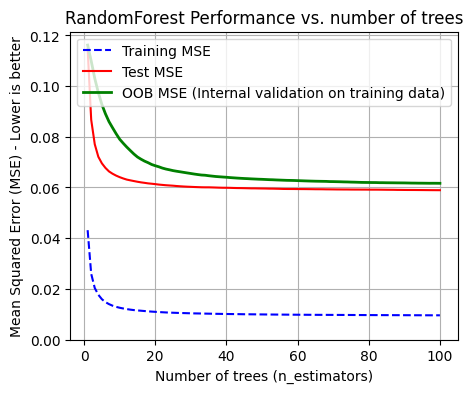

In [13]:
# Training of the full Random Forest 
MAX_ESTIMATORS = 100
rfr = RandomForestRegressor(n_estimators=MAX_ESTIMATORS, 
                            max_features='sqrt',
                            random_state=42, 
                            oob_score=True, n_jobs=-1) 
rfr.fit(X_train, y_train)
evaluate_progression_ensemble(rfr,MAX_ESTIMATORS, X_train, X_test, name = 'RandomForest')

   Decile  Avg_Actual  Avg_Predicted  Lift_to_Base
0       1    0.026597       0.000000      0.501004
1       2    0.026254       0.000000      0.494546
2       3    0.033186       0.009665      0.625128
3       4    0.039624       0.016137      0.746413
4       5    0.043805       0.025239      0.825169
5       6    0.047788       0.036409      0.900184
6       7    0.054422       0.052541      1.025160
7       8    0.062734       0.074498      1.181724
8       9    0.076352       0.112996      1.438258
9      10    0.120102       0.250735      2.262389


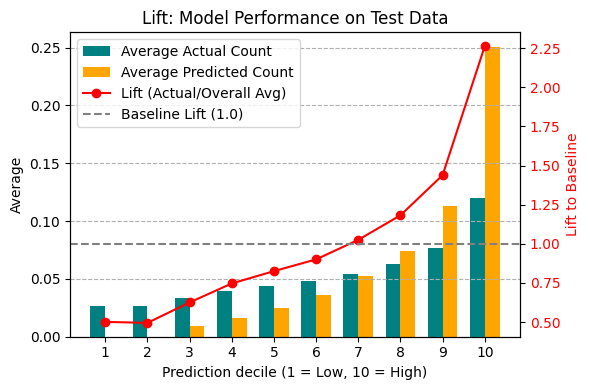

In [14]:
y_pred = rfr.predict(X_test)
results_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})

# Create 10 bins (deciles)
results_df['Decile'] = pd.qcut(results_df['Predicted'].rank(method='first'), q=10, labels=False)

# Group by Decile and calculate the mean for both Actual and Predicted
decile_summary = results_df.groupby('Decile').agg(
    Avg_Actual=('Actual', 'mean'),
    Avg_Predicted=('Predicted', 'mean'),
    Count=('Actual', 'size')
).reset_index()

# Rename the Decile index to start from 1 instead of 0
decile_summary['Decile'] = decile_summary['Decile'] + 1

overall_avg_actual = results_df['Actual'].mean()


decile_summary['Lift_to_Base'] = decile_summary['Avg_Actual'] / overall_avg_actual

# Print the summary
print(decile_summary[['Decile', 'Avg_Actual', 'Avg_Predicted', 'Lift_to_Base']])

fig, ax1 = plt.subplots(figsize=(6, 4))

# Plotting the Average Actual and Predicted Counts (Primary Axis)
bar_width = 0.35
x = np.arange(len(decile_summary))

rects1 = ax1.bar(x - bar_width/2, decile_summary['Avg_Actual'], bar_width, label='Average Actual Count', color='teal')
rects2 = ax1.bar(x + bar_width/2, decile_summary['Avg_Predicted'], bar_width, label='Average Predicted Count', color='orange')

ax1.set_xlabel('Prediction decile (1 = Low, 10 = High)')
ax1.set_ylabel('Average', color='black')
ax1.set_title('Lift: Model Performance on Test Data')
ax1.set_xticks(x)
ax1.set_xticklabels(decile_summary['Decile'])
ax1.grid(axis='y', linestyle='--')

# Adding a second axis for the Lift
ax2 = ax1.twinx()
ax2.plot(x, decile_summary['Lift_to_Base'], color='red', marker='o', linestyle='-', label='Lift (Actual/Overall Avg)')
ax2.set_ylabel('Lift to Baseline', color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.axhline(1.0, color='gray', linestyle='--', label='Baseline Lift (1.0)')
# One legend for both axes, top left (above the short bars of the low deciles)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc='upper left')

plt.tight_layout()
plt.savefig('liftRF')
plt.show()


The lift plot divides the test dataset into deciles on the basis of the model’s predictions (ascending orange bars). On the test data, the average observation can additionally be plotted (turquoise bars). These should also be ascending. The ratio of the average observed value in a decile to the average value in the data is referred to as **lift**.

<div class="alert alert-block alert-success">
<b>Interpretation of the results</b>    
For this dataset, bootstrapping in particular leads to a good prediction.
Adding feature bagging, which leads to the Random Forest, improves the prediction further. 
Although the model tends to overfit on the training data, good predictions are achieved on new data. Considering the OOB error is a very useful measure for obtaining an assessment of the prediction on test data during the training process.
The number of trees improves the prediction further. At some point, the improvement here has a strongly diminishing marginal benefit, so that the improvement no longer justifies the additional computing power.
We see that the model does indeed succeed in differentiating the test claims. Nevertheless, the lift plot is not particularly good. In particular, the predicted values deviate strongly from the values that actually occurred (difference between turquoise / orange bars).

</div>


<h2 style="color:#0050A0;">Block 3: Artificial neural network</h2>

We now model the same target variable as in Block 2 with a simple artificial neural network (ANN). For this, we use the Keras library. Here, we use the information that the number of claims is a non-negative integer. For this reason, a Poisson distribution is often assumed for it. This can also be carried over into the models. An ANN can thus fit seamlessly into the Poisson maximum likelihood method that is common in non-life insurance.


<div class="alert alert-block alert-info">
<b>Procedure in this block:</b> 
    
- Splitting the dataset into training and test data in a customary ratio (80% to 20%). Other splits (e.g. 70% to 30%) would also be permissible given the size of the data. Now, the exposure is additionally considered as a weighting of the target variable. For the ANN, the features are standardised, as the predictions are otherwise less stable (to illustrate this, one can train the model on the X_train data (non-standardised) instead of on X_train_processed (standardised)).
- Creation of an ANN
- In doing so, the output is multiplied by the exposure. This has the effect that the neural network models ClaimNb/Exposure. A common modelling approach in non-life insurance for frequency models.
</div>



<div class="alert alert-block alert-warning">
<b>Scope and preview of Module 7:</b>

In this module, artificial neural networks are considered as a **supervised learning method**, specifically as a feedforward network for a regression problem (Poisson modelling of the claim frequency). The ANN thus fits in with the supervised methods covered previously (cf. Block 2 of this Jupyter notebook: regression trees, Random Forest). Further aspects of artificial neural networks, including details of the training process (forward pass, backpropagation, learning rate, epochs) as well as topics of generative AI, follow in **Module 7**. 
</div>

In [15]:
#Loading the necessary libraries
import tensorflow as tf
from tensorflow import keras
tf.get_logger().setLevel("ERROR")  # hide TensorFlow deprecation notices
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    FunctionTransformer,
    StandardScaler,
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [16]:
# Identify target variable (ClaimNb) and exposure
X = data.drop('ClaimNb', axis=1).select_dtypes(include=np.number)
y = data['ClaimNb'].astype(float) 
exposure =  X['Exposure']
X = X.drop('Exposure', axis=1)

# We need to split X, y, exposure  together
X_train, X_test, y_train, y_test, exposure_train, exposure_test = train_test_split(
    X, y, exposure, test_size=0.2, random_state=42
)

# Standardisation of the features
def clip_and_scale(upper):
    pipe = Pipeline(
        steps=[
            ("clip", FunctionTransformer(lambda x: np.clip(x, a_min=0, a_max=upper))),
            ("scale", StandardScaler()),
        ]
    )
    return pipe


density = Pipeline(
    steps=[
        ("log", FunctionTransformer(lambda x: np.log(x).round(2))),
        ("scale", StandardScaler()),
    ]
)

# Combining the standardisations
preprocessor = ColumnTransformer(
    transformers=[
        (
            "scale",
            clip_and_scale([15,20, 90, 150]),
            ["VehPower","VehAge", "DrivAge", "BonusMalus"],
        ),
        ("density", density, ["Density"]),
    ],
    verbose_feature_names_out=False,
)



# Apply the preprocessing to the training and test data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Ensure that the data are in the correct format (numpy arrays)
X_train_processed = X_train_processed.astype(np.float32)
X_test_processed = X_test_processed.astype(np.float32)
y_train = y_train.values.astype(np.float32)
y_test = y_test.values.astype(np.float32)


print(f"Dimension X_train_processed: {X_train_processed.shape}")
print(f"Dimension y_train: {y_train.shape}")

print(f" Excerpt from X_train: \n {X_train.head()}")
print(f" Excerpt from X_train_processed: \n {X_train_processed[range(5)]}")

Dimension X_train_processed: (542410, 5)
Dimension y_train: (542410,)
 Excerpt from X_train: 
         VehPower  VehAge  DrivAge  BonusMalus  Density
406477         6       5       59          50       96
393150        10      11       61          50      111
252885         7       4       42          50       19
260652         6       4       52          50       16
661256         5       3       71          50      538
 Excerpt from X_train_processed: 
 [[-0.22132044 -0.36587745  0.95575494 -0.62495196 -0.7593107 ]
 [ 1.7314874   0.7456736   1.0973028  -0.62495196 -0.6791031 ]
 [ 0.26688153 -0.55113596 -0.24740154 -0.62495196 -1.6255535 ]
 [-0.22132044 -0.55113596  0.46033758 -0.62495196 -1.7164555 ]
 [-0.7095224  -0.73639446  1.8050419  -0.62495196  0.165751  ]]


We will now create an artificial neural network. For this, we use Keras and TensorFlow. Individual structures are defined via keras.layers:

- First, the input dimensions are specified.
- Subsequently, further layers (hidden layers) are connected. The connection is made by passing the outputs of one layer (x in the code) as input to the next layer (x in the argument of the function keras.layers.Dense()(x)).
- In each case, an activation function has to be selected, which can also differ from layer to layer (hyperparameter).
- At the end, the link function of the Poisson distribution is applied by means of a further layer with one neuron and exponential activation.
- Through the subsequent multiplication by the exposure, the target variable is weighted with the exposure. Finally, the model is created.
  
In the summary table, we see the specified model sizes and the parameters of the ANN to be estimated. For example, in the first layer the inputs (dimension 5) are passed into a layer with 20 neurons. This results in 5*20 parameters for the connections and an additional 20 bias terms (one per neuron).

In [17]:
# Defining the neural network
def create_fnn(seed, n_features, hidden_layers):
    # Clean up
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    tf.random.set_seed(seed)
    random.seed(seed)

    # Inputs
    design_input = keras.layers.Input(shape=(n_features,))
    volume_input = keras.layers.Input(shape=(1,))

    x = design_input

    # Layers
    for q in hidden_layers:
        x = keras.layers.Dense(q, activation="tanh")(x)
    x = keras.layers.Dense(1, activation="exponential")(x)

    # Exposure weighting
    output = keras.layers.Multiply()([x, volume_input])

    model = keras.Model(inputs=[design_input, volume_input], outputs=output)

    return model


SEED = 42
M_FEAT = X_train_processed.shape[1]  # number of features
HIDDEN = [20, 15, 10]

# Creating a model with three hidden layers
model = create_fnn(SEED, n_features=M_FEAT, hidden_layers=HIDDEN)
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 5)                 │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 20)                │             120 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 15)                │             315 │ dense[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_2 (Dense)               │ (None, 10)                │             160 │ dense_1[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_3 (Dense)               │ (None, 1)                 │              11 │ dense_2[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ input_layer_1 (InputLayer)    │ (None, 1)                 │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multiply (Multiply)           │ (None, 1)                 │               0 │ dense_3[0][0],             │
│                               │                           │                 │ input_layer_1[0][0]        │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 606 (2.37 KB)

 Trainable params: 606 (2.37 KB)

 Non-trainable params: 0 (0.00 B)

Now we train the ANN. First, we use the original data (X_train) for this. Then we use the standardised data (X_train_processed). In each case, we train with a batch size of 5000 data points. We set aside 20% of the data (the last 20% of the training data, the same in every epoch) for validation during training itself (comparable to the OOB estimator of the Random Forest). 
This results in a total of 87 calculation steps (542410 * 80%/5000 ≈ 86.79) per epoch. We repeat this 100 times and successively adjust the weights of the ANN to be trained.

In [18]:
# Training the ANN on the original data
print(f"--- Training the ANN on the original data ---")
model2 = create_fnn(SEED, n_features=M_FEAT, hidden_layers=HIDDEN)  # fresh network
model2.compile(loss="poisson", optimizer="nadam")
history2 = model2.fit(
    [X_train, exposure_train],
    y_train,
    validation_split=0.2,
    batch_size=5000,
    epochs=100,
    verbose=2
)


# Training the ANN on the standardised data
print(f"--- Training the ANN on the standardised data ---")
model = create_fnn(SEED, n_features=M_FEAT, hidden_layers=HIDDEN)   # fresh network
model.compile(loss="poisson", optimizer="nadam")
history = model.fit(
    [X_train_processed, exposure_train],
    y_train,
    validation_split=0.2,
    batch_size=5000,
    epochs=100,
    verbose=2
)

--- Training the ANN on the original data ---
Epoch 1/100
87/87 - 1s - 16ms/step - loss: 0.4360 - val_loss: 0.2216
Epoch 2/100
87/87 - 0s - 4ms/step - loss: 0.2152 - val_loss: 0.2163
Epoch 3/100
87/87 - 0s - 4ms/step - loss: 0.2134 - val_loss: 0.2160
Epoch 4/100
87/87 - 0s - 4ms/step - loss: 0.2132 - val_loss: 0.2159
Epoch 5/100
87/87 - 0s - 4ms/step - loss: 0.2130 - val_loss: 0.2157
Epoch 6/100
87/87 - 0s - 4ms/step - loss: 0.2125 - val_loss: 0.2148
Epoch 7/100
87/87 - 0s - 4ms/step - loss: 0.2122 - val_loss: 0.2145
Epoch 8/100
87/87 - 0s - 4ms/step - loss: 0.2118 - val_loss: 0.2154
Epoch 9/100
87/87 - 0s - 3ms/step - loss: 0.2119 - val_loss: 0.2142
Epoch 10/100
87/87 - 0s - 4ms/step - loss: 0.2117 - val_loss: 0.2143
Epoch 11/100
87/87 - 0s - 4ms/step - loss: 0.2115 - val_loss: 0.2141
Epoch 12/100
87/87 - 0s - 4ms/step - loss: 0.2113 - val_loss: 0.2138
Epoch 13/100
87/87 - 0s - 4ms/step - loss: 0.2112 - val_loss: 0.2138
Epoch 14/100
87/87 - 0s - 4ms/step - loss: 0.2113 - val_loss: 0.2

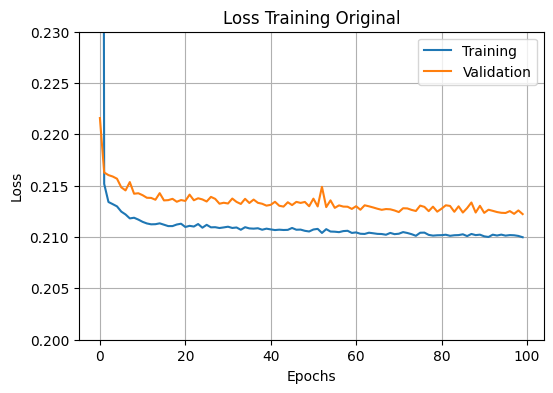

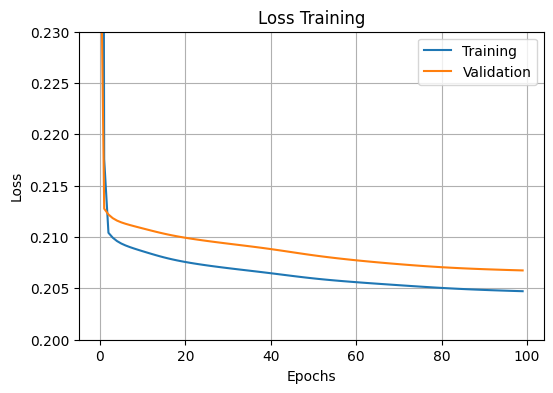

In [19]:
# Visualisation of the training history – original
fig, ax = plt.subplots(figsize=(6, 4)) 

(
    pd.DataFrame(history2.history)
    .rename(columns={"loss": "Training", "val_loss": "Validation"})
    .plot(ax=ax, xlabel="Epochs", ylabel="Loss", title="Loss Training Original", grid=True)
)

ax.set_ylim(0.20, 0.23)

fig.savefig('NN_loss_plot_explicit_original.png')
plt.show()




# Visualisation of the training history – standardised
fig, ax = plt.subplots(figsize=(6, 4)) 

(
    pd.DataFrame(history.history)
    .rename(columns={"loss": "Training", "val_loss": "Validation"})
    .plot(ax=ax, xlabel="Epochs", ylabel="Loss", title="Loss Training", grid=True)
)

ax.set_ylim(0.20, 0.23)

fig.savefig('NN_loss_plot_explicit.png')
plt.show()


4238/4238 ━━━━━━━━━━━━━━━━━━━━ 3s 683us/step
   Decile  Avg_Actual  Avg_Predicted  Lift_to_Base
0       1    0.019541       0.003570      0.365953
1       2    0.023451       0.009438      0.439176
2       3    0.032743       0.017490      0.613189
3       4    0.042625       0.028093      0.798250
4       5    0.043655       0.039741      0.817524
5       6    0.048083       0.051533      0.900448
6       7    0.057596       0.063227      1.078604
7       8    0.062758       0.073828      1.175278
8       9    0.072861       0.087258      1.364483
9      10    0.130669       0.162600      2.447050


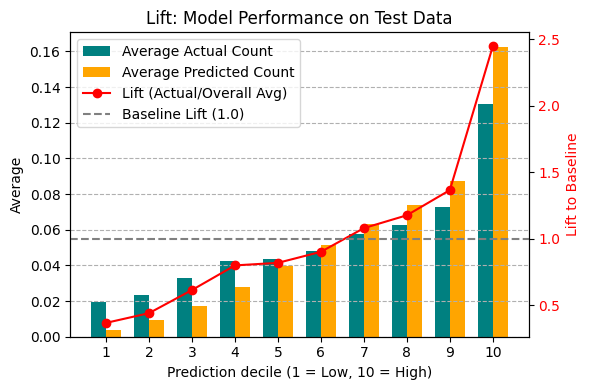

In [20]:
# Create lift plot
y_pred = model.predict([X_test_processed, exposure_test])
results_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred.flatten()})

# Create 10 bins (deciles)
results_df['Decile'] = pd.qcut(results_df['Predicted'].rank(method='first'), q=10, labels=False)

# Group by Decile and calculate the mean for both Actual and Predicted
decile_summary = results_df.groupby('Decile').agg(
    Avg_Actual=('Actual', 'mean'),
    Avg_Predicted=('Predicted', 'mean'),
    Count=('Actual', 'size')
).reset_index()

# Rename the Decile index to start from 1 instead of 0
decile_summary['Decile'] = decile_summary['Decile'] + 1

overall_avg_actual = results_df['Actual'].mean()


decile_summary['Lift_to_Base'] = decile_summary['Avg_Actual'] / overall_avg_actual

# Print the summary
print(decile_summary[['Decile', 'Avg_Actual', 'Avg_Predicted', 'Lift_to_Base']])

fig, ax1 = plt.subplots(figsize=(6, 4))

# Plotting the Average Actual and Predicted Counts (Primary Axis)
bar_width = 0.35
x = np.arange(len(decile_summary))

rects1 = ax1.bar(x - bar_width/2, decile_summary['Avg_Actual'], bar_width, label='Average Actual Count', color='teal')
rects2 = ax1.bar(x + bar_width/2, decile_summary['Avg_Predicted'], bar_width, label='Average Predicted Count', color='orange')

ax1.set_xlabel('Prediction decile (1 = Low, 10 = High)')
ax1.set_ylabel('Average', color='black')
ax1.set_title('Lift: Model Performance on Test Data')
ax1.set_xticks(x)
ax1.set_xticklabels(decile_summary['Decile'])
ax1.grid(axis='y', linestyle='--')

# Adding a second axis for the Lift
ax2 = ax1.twinx()
ax2.plot(x, decile_summary['Lift_to_Base'], color='red', marker='o', linestyle='-', label='Lift (Actual/Overall Avg)')
ax2.set_ylabel('Lift to Baseline', color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.axhline(1.0, color='gray', linestyle='--', label='Baseline Lift (1.0)')
# One legend for both axes, top left (above the short bars of the low deciles)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc='upper left')

plt.tight_layout()
plt.savefig('lift')
plt.show()



<div class="alert alert-block alert-success">
<b>Interpretation of the results</b> The neural network succeeds very well in differentiating with respect to risk features.
Standardising the data is crucial in order to obtain stable predictions. This is mainly for numerical reasons. The training process of the neural network comprises the adjustment of a very large number of weights. If a single feature can, for example, take on very large values (Density in the original), the leverage of the weights linked to this input on the overall prediction is very large. Changes in the input thus have a large effect on the prediction (oscillation). Standardisation mitigates this effect and leads to better, more stable predictions. It is often not at all crucial which type of standardisation is applied. 
   
The lift plot shows a good differentiation of the data on test data. Claims are differentiated better than with the Random Forest (turquoise and orange bars are considerably more similar).
</div>
